In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np


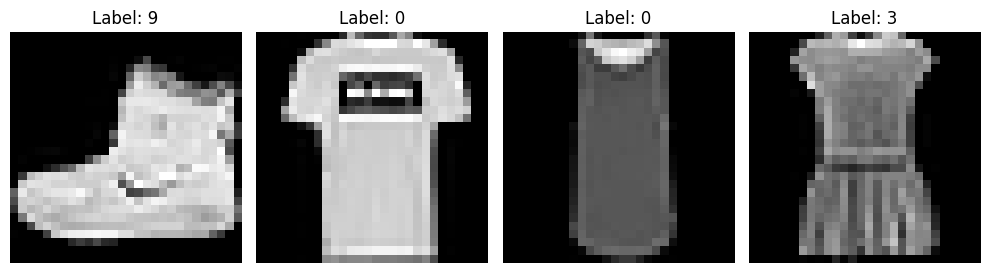

In [2]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Print 4 images in a row
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
num_classes = 10
input_shape = (28, 28, 1)

In [4]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [5]:
from keras import layers

In [6]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=layers.ReLU()(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model=keras.Model(inputs,outputs)

In [7]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 batch_normalization (BatchN  (None, 26, 26, 32)       128       
 ormalization)                                                   
                                                                 
 re_lu (ReLU)                (None, 26, 26, 32)        0         
                                                                 
 flatten (Flatten)           (None, 21632)             0         
                                                                 
 dense (Dense)               (None, 10)                216330    
                                                             

In [8]:
batch_size = 128
epochs = 150

model.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history=model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 5s 6ms/step - loss: 0.9757 - accuracy: 0.6809 - val_loss: 0.8781 - val_accuracy: 0.7777
Epoch 2/150
422/422 [==============================] - 2s 5ms/step - loss: 0.5767 - accuracy: 0.8066 - val_loss: 0.5211 - val_accuracy: 0.8242
Epoch 3/150
422/422 [==============================] - 2s 5ms/step - loss: 0.4968 - accuracy: 0.8320 - val_loss: 0.4710 - val_accuracy: 0.8345
Epoch 4/150
422/422 [==============================] - 2s 5ms/step - loss: 0.4527 - accuracy: 0.8465 - val_loss: 0.4350 - val_accuracy: 0.8478
Epoch 5/150
422/422 [==============================] - 2s 5ms/step - loss: 0.4232 - accuracy: 0.8569 - val_loss: 0.4165 - val_accuracy: 0.8527
Epoch 6/150
422/422 [==============================] - 2s 5ms/step - loss: 0.4014 - accuracy: 0.8634 - val_loss: 0.3955 - val_accuracy: 0.8612
Epoch 7/150
422/422 [==============================] - 2s 5ms/step - loss: 0.3843 - accuracy: 0.8690 - val_loss: 0.3841 - val_accuracy: 0.8645

Epoch 58/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2065 - accuracy: 0.9300 - val_loss: 0.2804 - val_accuracy: 0.9025
Epoch 59/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2059 - accuracy: 0.9301 - val_loss: 0.2766 - val_accuracy: 0.9008
Epoch 60/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2043 - accuracy: 0.9310 - val_loss: 0.2777 - val_accuracy: 0.9022
Epoch 61/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2030 - accuracy: 0.9311 - val_loss: 0.2781 - val_accuracy: 0.9022
Epoch 62/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2016 - accuracy: 0.9314 - val_loss: 0.2760 - val_accuracy: 0.9047
Epoch 63/150
422/422 [==============================] - 2s 5ms/step - loss: 0.2005 - accuracy: 0.9320 - val_loss: 0.2762 - val_accuracy: 0.9035
Epoch 64/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1995 - accuracy: 0.9324 - val_loss: 0.2754 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1529 - accuracy: 0.9503 - val_loss: 0.2713 - val_accuracy: 0.9083
Epoch 116/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1525 - accuracy: 0.9508 - val_loss: 0.2703 - val_accuracy: 0.9082
Epoch 117/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1514 - accuracy: 0.9518 - val_loss: 0.2703 - val_accuracy: 0.9090
Epoch 118/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1509 - accuracy: 0.9507 - val_loss: 0.2721 - val_accuracy: 0.9082
Epoch 119/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1505 - accuracy: 0.9519 - val_loss: 0.2708 - val_accuracy: 0.9097
Epoch 120/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1496 - accuracy: 0.9524 - val_loss: 0.2706 - val_accuracy: 0.9080
Epoch 121/150
422/422 [==============================] - 2s 5ms/step - loss: 0.1492 - accuracy: 0.9520 - val_loss: 0.2708 - val_ac

In [9]:
class Weibull(keras.layers.Layer):
    def __init__(self, shape, scale, **kwargs):
        super().__init__(**kwargs)
        self.shape = shape
        self.scale = scale

    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)
        
        # Avoid division by zero or negative scale
        z = tf.math.maximum(inputs / self.scale, 0.0)

        # Weibull CDF: 1 - exp(-(z)^shape)
        weibull_cdf = 1.0 - tf.exp(-tf.pow(z, self.shape))

        # Optional: hard-zero for negative inputs (domain of Weibull CDF is x ≥ 0)
        output = tf.where(inputs < 0, 0.0, weibull_cdf)

        return output

    def get_config(self):
        config = super().get_config()
        config.update({
            "shape": self.shape,
            "scale": self.scale,
        })
        return config


In [10]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=Weibull(shape=1.5,scale=1)(x)#2,5
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_ray=keras.Model(inputs,outputs)

In [11]:
model_ray.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 batch_normalization_1 (Batc  (None, 26, 26, 32)       128       
 hNormalization)                                                 
                                                                 
 weibull (Weibull)           (None, 26, 26, 32)        0         
                                                                 
 flatten_1 (Flatten)         (None, 21632)             0         
                                                                 
 dense_1 (Dense)             (None, 10)                216330    
                                                           

In [12]:
model_ray.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_ray=model_ray.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 4s 9ms/step - loss: 1.0617 - accuracy: 0.6906 - val_loss: 1.0134 - val_accuracy: 0.7590
Epoch 2/150
422/422 [==============================] - 4s 9ms/step - loss: 0.6357 - accuracy: 0.7933 - val_loss: 0.5786 - val_accuracy: 0.8062
Epoch 3/150
422/422 [==============================] - 4s 8ms/step - loss: 0.5418 - accuracy: 0.8224 - val_loss: 0.5094 - val_accuracy: 0.8240
Epoch 4/150
422/422 [==============================] - 4s 8ms/step - loss: 0.4902 - accuracy: 0.8370 - val_loss: 0.4712 - val_accuracy: 0.8355
Epoch 5/150
422/422 [==============================] - 4s 9ms/step - loss: 0.4565 - accuracy: 0.8479 - val_loss: 0.4440 - val_accuracy: 0.8432
Epoch 6/150
422/422 [==============================] - 4s 9ms/step - loss: 0.4320 - accuracy: 0.8558 - val_loss: 0.4254 - val_accuracy: 0.8485
Epoch 7/150
422/422 [==============================] - 4s 8ms/step - loss: 0.4131 - accuracy: 0.8608 - val_loss: 0.4094 - val_accuracy: 0.8562

Epoch 58/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2329 - accuracy: 0.9206 - val_loss: 0.2826 - val_accuracy: 0.8995
Epoch 59/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2316 - accuracy: 0.9216 - val_loss: 0.2811 - val_accuracy: 0.9002
Epoch 60/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2301 - accuracy: 0.9221 - val_loss: 0.2815 - val_accuracy: 0.9010
Epoch 61/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2289 - accuracy: 0.9226 - val_loss: 0.2806 - val_accuracy: 0.8992
Epoch 62/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2276 - accuracy: 0.9222 - val_loss: 0.2812 - val_accuracy: 0.8995
Epoch 63/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2264 - accuracy: 0.9229 - val_loss: 0.2804 - val_accuracy: 0.9003
Epoch 64/150
422/422 [==============================] - 4s 8ms/step - loss: 0.2253 - accuracy: 0.9236 - val_loss: 0.2817 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 4s 8ms/step - loss: 0.1796 - accuracy: 0.9416 - val_loss: 0.2645 - val_accuracy: 0.9082
Epoch 116/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1786 - accuracy: 0.9421 - val_loss: 0.2638 - val_accuracy: 0.9067
Epoch 117/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1783 - accuracy: 0.9424 - val_loss: 0.2630 - val_accuracy: 0.9062
Epoch 118/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1774 - accuracy: 0.9429 - val_loss: 0.2630 - val_accuracy: 0.9072
Epoch 119/150
422/422 [==============================] - 4s 8ms/step - loss: 0.1768 - accuracy: 0.9427 - val_loss: 0.2632 - val_accuracy: 0.9080
Epoch 120/150
422/422 [==============================] - 4s 8ms/step - loss: 0.1761 - accuracy: 0.9428 - val_loss: 0.2649 - val_accuracy: 0.9068
Epoch 121/150
422/422 [==============================] - 4s 10ms/step - loss: 0.1754 - accuracy: 0.9433 - val_loss: 0.2640 - val_a

the value of breast cancer

| Metric   | Weibull CDF Activation | ReLU                |
| -------- | ---------------------- | ------------------- |
| RMSE     | 0.0337                 | 0.03                |
| MAE      | 0.0231                 | 0.03                |
| MAPE     | 14.22%                 | 15.73%              |

In [13]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=tf.keras.activations.gelu(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_gelu=keras.Model(inputs,outputs)

In [14]:
model_gelu.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.00001), metrics=["accuracy"])

history_gelu=model_gelu.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/150
422/422 [==============================] - 4s 9ms/step - loss: 0.9324 - accuracy: 0.6944 - val_loss: 0.9189 - val_accuracy: 0.7732
Epoch 2/150
422/422 [==============================] - 3s 8ms/step - loss: 0.5652 - accuracy: 0.8089 - val_loss: 0.5181 - val_accuracy: 0.8195
Epoch 3/150
422/422 [==============================] - 3s 8ms/step - loss: 0.4885 - accuracy: 0.8350 - val_loss: 0.4665 - val_accuracy: 0.8377
Epoch 4/150
422/422 [==============================] - 4s 8ms/step - loss: 0.4475 - accuracy: 0.8472 - val_loss: 0.4344 - val_accuracy: 0.8445
Epoch 5/150
422/422 [==============================] - 4s 9ms/step - loss: 0.4192 - accuracy: 0.8571 - val_loss: 0.4157 - val_accuracy: 0.8510
Epoch 6/150
422/422 [==============================] - 4s 9ms/step - loss: 0.3994 - accuracy: 0.8637 - val_loss: 0.3982 - val_accuracy: 0.8577
Epoch 7/150
422/422 [==============================] - 3s 8ms/step - loss: 0.3828 - accuracy: 0.8688 - val_loss: 0.3874 - val_accuracy: 0.8650

Epoch 58/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2049 - accuracy: 0.9309 - val_loss: 0.2843 - val_accuracy: 0.8978
Epoch 59/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2032 - accuracy: 0.9320 - val_loss: 0.2855 - val_accuracy: 0.8958
Epoch 60/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2021 - accuracy: 0.9321 - val_loss: 0.2841 - val_accuracy: 0.8997
Epoch 61/150
422/422 [==============================] - 3s 8ms/step - loss: 0.2008 - accuracy: 0.9325 - val_loss: 0.2841 - val_accuracy: 0.8982
Epoch 62/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1996 - accuracy: 0.9335 - val_loss: 0.2837 - val_accuracy: 0.8987
Epoch 63/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1978 - accuracy: 0.9334 - val_loss: 0.2849 - val_accuracy: 0.8995
Epoch 64/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1968 - accuracy: 0.9350 - val_loss: 0.2841 - val_accuracy:

Epoch 115/150
422/422 [==============================] - 4s 8ms/step - loss: 0.1503 - accuracy: 0.9508 - val_loss: 0.2829 - val_accuracy: 0.9052
Epoch 116/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1496 - accuracy: 0.9514 - val_loss: 0.2834 - val_accuracy: 0.9052
Epoch 117/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1487 - accuracy: 0.9520 - val_loss: 0.2824 - val_accuracy: 0.9052
Epoch 118/150
422/422 [==============================] - 4s 8ms/step - loss: 0.1480 - accuracy: 0.9515 - val_loss: 0.2827 - val_accuracy: 0.9040
Epoch 119/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1474 - accuracy: 0.9518 - val_loss: 0.2835 - val_accuracy: 0.9042
Epoch 120/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1471 - accuracy: 0.9521 - val_loss: 0.2823 - val_accuracy: 0.9045
Epoch 121/150
422/422 [==============================] - 3s 8ms/step - loss: 0.1462 - accuracy: 0.9527 - val_loss: 0.2845 - val_ac

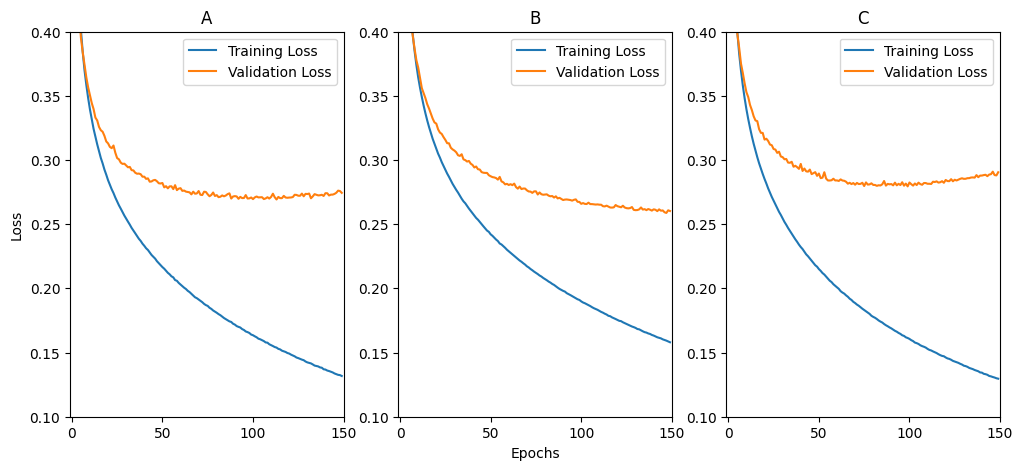

<Figure size 640x480 with 0 Axes>

In [15]:
def plot_loss_comparison2(relu_history, custom_history1,custom_history2 ):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 0.1
    y_max = 0.4
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('A')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('B')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('C')
    plt.ylim(y_min, y_max)
    plt.xlim(-1, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()

# Usage
plot_loss_comparison2(history,history_ray,history_gelu)

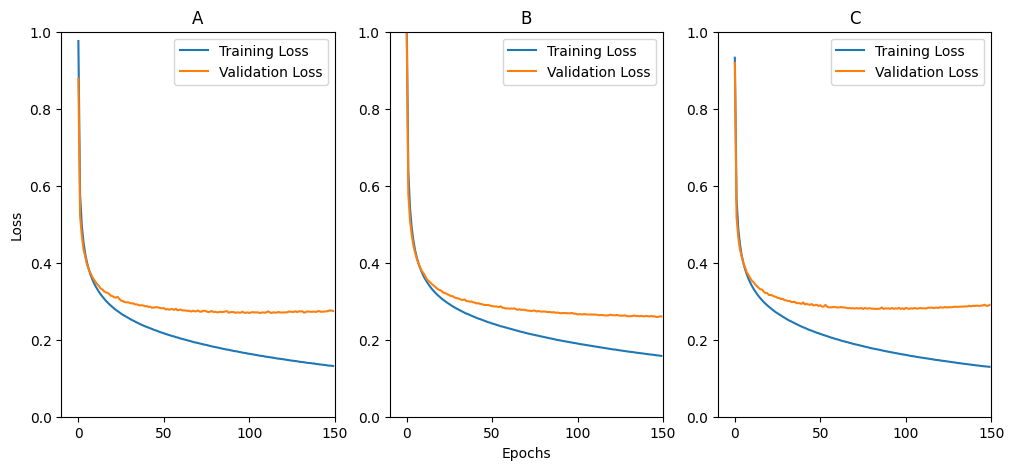

<Figure size 640x480 with 0 Axes>

In [18]:
def plot_loss_comparison(relu_history, custom_history1,custom_history2 ):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 0
    y_max = 1
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('A')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('B')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim( -10, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('C')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()

# Usage
plot_loss_comparison(history,history_ray,history_gelu)

In [17]:
score_relu = model.evaluate(x_test, y_test, verbose=0)
score_weilu = model_ray.evaluate(x_test, y_test, verbose=0)
score_gelu = model_gelu.evaluate(x_test, y_test, verbose=0)
print("Relu accuracy:", score_relu)
print("Weilu accuracy:", score_weilu)
print("Gelu accuracy:", score_gelu)

Relu accuracy: [0.28871485590934753, 0.901199996471405]
Weilu accuracy: [0.27617642283439636, 0.9017999768257141]
Gelu accuracy: [0.30474454164505005, 0.896399974822998]
